<a href="https://colab.research.google.com/github/Guo-Tang-26/DS4420-Project/blob/main/DS4420_Project_Bayesian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path("/content/drive/MyDrive/charles_river_data_2026-11-18")
csv_path = data_dir / "daily_merged.csv"

df = pd.read_csv(csv_path, parse_dates=["date"])

print(df.shape)
display(df[["date", "discharge_cfs_mean"]].head())

(34805, 19)


,date,discharge_cfs_mean
0,1931-08-04,45.0
1,1931-08-05,38.0
2,1931-08-06,38.0
3,1931-08-07,42.0
4,1931-08-08,54.0


#Bayesian Logistic Regression - Charles River at Waltham

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

In [4]:
rng = np.random.default_rng(42)
THRESHOLD = 1000  # cfs, daily mean (just below the NWS action stage)
HORIZON = 3
TARGET = "discharge_cfs_mean"
FEATURES = ["log_q", "rise_3d", "rain_today", "rain_3d", "tmean_f"]
DATE = "date"

In [5]:
daily = df.copy()
daily[DATE] = pd.to_datetime(daily[DATE]).dt.normalize()
daily = daily.set_index(DATE).sort_index()[[TARGET, "precip_in", "tmean_f"]].asfreq("D")
daily = daily.apply(pd.to_numeric, errors="coerce")
train_end = daily.index[int(len(daily) * 0.70)]  # same split as the LSTM
test_start = daily.index[int(len(daily) * 0.85)]

# fill missing weather using only training medians and keep missing flow as NaN.
weather = ["precip_in", "tmean_f"]
daily[weather] = daily[weather].fillna(daily.loc[daily.index < train_end, weather].median())

# features on day t use only data up to day t.
q = daily[TARGET]
daily["log_q"] = np.log(q / THRESHOLD)
daily["rise_3d"] = daily["log_q"] - daily["log_q"].shift(3)
daily["rain_today"] = daily["precip_in"]
daily["rain_3d"] = daily["precip_in"].shift(1).rolling(3).sum()  # rain 1-3 days ago

# target for h days ahead: is flow on day t+h at or above the threshold?
labels = [f"y{h}" for h in range(1, HORIZON + 1)]
for h in range(1, HORIZON + 1):
    daily[f"y{h}"] = (q.shift(-h) >= THRESHOLD).astype(float).where(q.shift(-h).notna())

# keep all labels of a row in one split, like the LSTM windows. the validation years are
# not used because there is nothing to tune.
rows = daily.dropna(subset=FEATURES + labels)
train = rows[rows.index + pd.Timedelta(days=HORIZON) < train_end]
test = rows[rows.index + pd.Timedelta(days=1) >= test_start]

scaler = StandardScaler().fit(train[FEATURES])
def design(d):
    return np.column_stack([np.ones(len(d)), scaler.transform(d[FEATURES])])
X_train, X_test = design(train), design(test)
names = ["intercept"] + FEATURES
print("Validation starts", train_end.date(), "| Test starts", test_start.date())
print(len(train), "train days,", len(test), "test days,", int(test["y1"].sum()), "test days at or above 1,000 cfs")

Validation starts 1998-04-17 | Test starts 2012-08-02
24357 train days, 5219 test days, 139 test days at or above 1,000 cfs


In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# y ~ Bernoulli(sigmoid(X w)) with a Normal(0, 10^2) prior on every weight.
def log_posterior(w, X, y, prior_sd=10):
    z = X @ w
    return np.sum(y * z - np.logaddexp(0, z)) - 0.5 * np.sum(w ** 2) / prior_sd ** 2

# random-walk Metropolis. log flow and the intercept are strongly correlated, so the
# proposal uses the posterior's shape at the maximum-likelihood fit (inverse Hessian).
def metropolis(X, y, n_iter=5000, burn_in=1000, chains=2):
    mle = LogisticRegression(C=np.inf, max_iter=5000).fit(X[:, 1:], y)
    w_hat = np.r_[mle.intercept_, mle.coef_.ravel()]
    p = sigmoid(X @ w_hat)
    d = X.shape[1]
    L = np.linalg.cholesky(np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None])) * 2.38 ** 2 / d)
    samples = np.zeros((chains, n_iter - burn_in, d))
    for c in range(chains):
        w = w_hat + L @ rng.standard_normal(d)
        lp, accepted = log_posterior(w, X, y), 0
        for i in range(n_iter):
            proposal = w + L @ rng.standard_normal(d)
            lp_new = log_posterior(proposal, X, y)
            if np.log(rng.random()) < lp_new - lp:
                w, lp, accepted = proposal, lp_new, accepted + 1
            if i >= burn_in:
                samples[c, i - burn_in] = w
        print(f"chain {c}: acceptance rate {accepted / n_iter:.2f}")
    return samples.reshape(-1, d), samples

# Gelman-Rubin R-hat for each weight; close to 1 means the chains agree.
def r_hat(s):
    n = s.shape[1]
    W = s.var(axis=1, ddof=1).mean(axis=0)
    B = n * s.mean(axis=1).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

1 day(s) ahead
chain 0: acceptance rate 0.28
chain 1: acceptance rate 0.27
max R-hat: 1.007
2 day(s) ahead
chain 0: acceptance rate 0.28
chain 1: acceptance rate 0.28
max R-hat: 1.007
3 day(s) ahead
chain 0: acceptance rate 0.28
chain 1: acceptance rate 0.28
max R-hat: 1.004


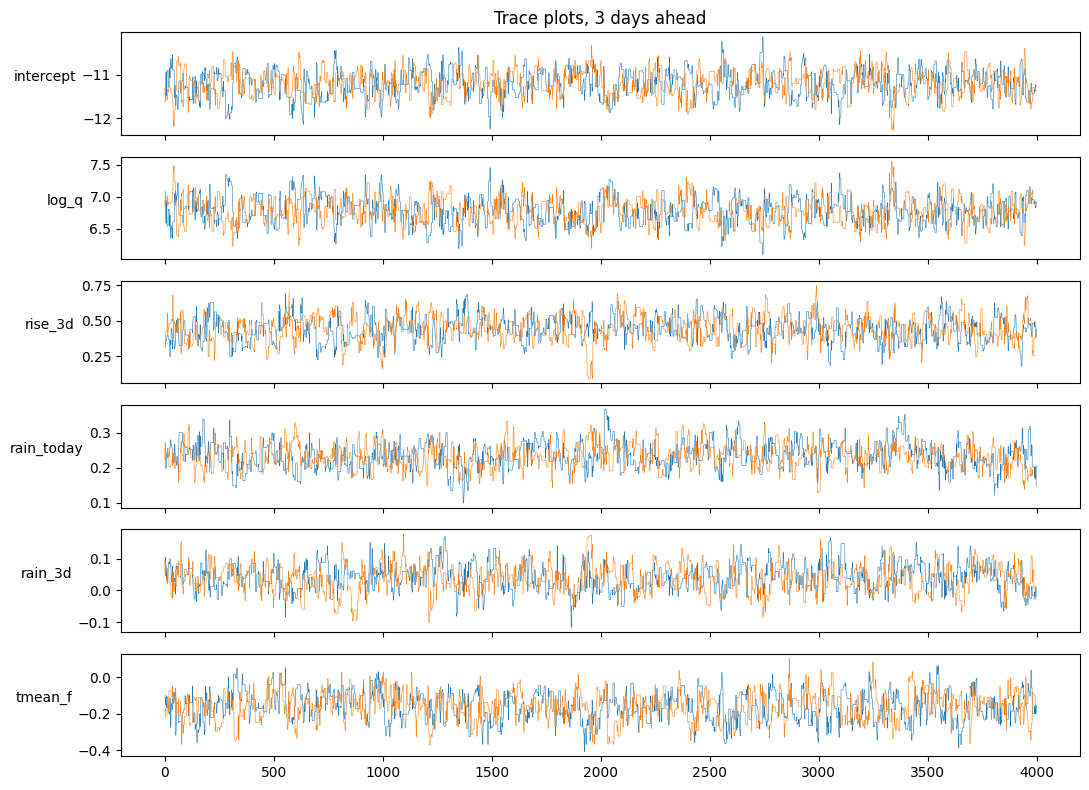

In [7]:
draws = {}
for h in range(1, HORIZON + 1):
    print(f"{h} day(s) ahead")
    draws[h], chains = metropolis(X_train, train[f"y{h}"].to_numpy())
    print("max R-hat:", r_hat(chains).max().round(3))

# trace plots for the last horizon fit
fig, axes = plt.subplots(len(names), 1, figsize=(11, 8), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(chains[:, :, j].T, lw=0.4)
    ax.set_ylabel(names[j], rotation=0, ha="right")
axes[0].set_title(f"Trace plots, {HORIZON} days ahead")
plt.tight_layout()
plt.show()

In [8]:
# posterior summary for 1 day ahead (weights are per +1 SD of each feature).
# a 90% interval that excludes 0 means the feature clearly matters.
w = draws[1]
display(pd.DataFrame({"mean": w.mean(0), "5%": np.quantile(w, 0.05, 0),
                      "95%": np.quantile(w, 0.95, 0)}, index=names).round(3))

,mean,5%,95%
intercept,-26.304,-28.135,-24.424
log_q,17.016,15.771,18.246
rise_3d,0.354,0.142,0.564
rain_today,0.530,0.431,0.621
rain_3d,-0.050,-0.150,0.047
tmean_f,-0.192,-0.395,-0.001


,Model,Days ahead,Brier score,PR-AUC
0,Bayesian,1,0.006,0.932
1,Persistence,1,0.009,0.689
2,Bayesian,2,0.011,0.778
3,Persistence,2,0.016,0.495
4,Bayesian,3,0.014,0.689
5,Persistence,3,0.021,0.384


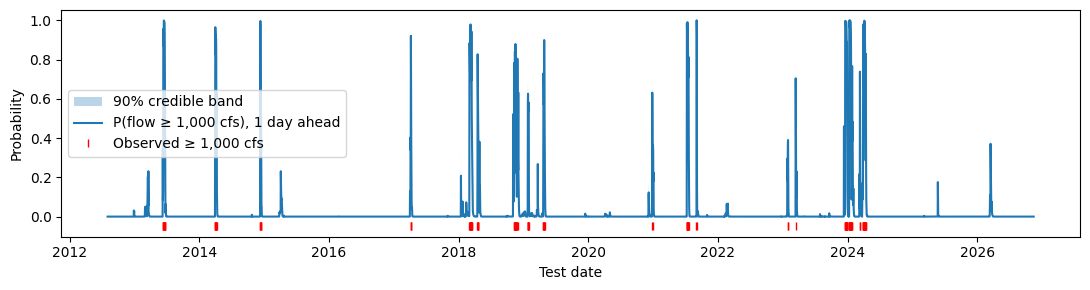

In [9]:
# each posterior draw gives a probability; average them for the forecast.
# persistence predicts that tomorrow is above the threshold if today is.
probs, rows_out = {}, []
for h in range(1, HORIZON + 1):
    y = test[f"y{h}"].to_numpy()
    probs[h] = sigmoid(X_test @ draws[h].T)  # (test days, posterior draws)
    persist = (test[TARGET] >= THRESHOLD).astype(float).to_numpy()
    for name, p in [("Bayesian", probs[h].mean(1)), ("Persistence", persist)]:
        rows_out.append([name, h, np.mean((p - y) ** 2), average_precision_score(y, p)])
display(pd.DataFrame(rows_out, columns=["Model", "Days ahead", "Brier score", "PR-AUC"]).round(3))

# plot day-ahead probabilities at their target dates with a 90% credible band.
dates = test.index + pd.Timedelta(days=1)
plt.figure(figsize=(11, 3))
plt.fill_between(dates, np.quantile(probs[1], 0.05, 1), np.quantile(probs[1], 0.95, 1), alpha=0.3, label="90% credible band")
plt.plot(dates, probs[1].mean(1), label="P(flow ≥ 1,000 cfs), 1 day ahead")
hit = test["y1"].to_numpy() == 1
plt.plot(dates[hit], np.full(hit.sum(), -0.05), "r|", label="Observed ≥ 1,000 cfs")
plt.ylabel("Probability")
plt.xlabel("Test date")
plt.legend()
plt.tight_layout()
plt.show()